In [1]:
import pandas as pd

train = pd.read_csv("C:/Users/RGUKT/Desktop/mobile_price_prediction/data/train.csv")
test = pd.read_csv("C:/Users/RGUKT/Desktop/mobile_price_prediction/data/test.csv")

print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

Training Shape: (2000, 21)
Testing Shape: (1000, 21)


In [2]:
#Feature Engineering with All Features
train["total_camera_mp"] = train["fc"] + train["pc"]
test["total_camera_mp"] = test["fc"] + test["pc"]

train["processor_score"] = train["n_cores"] * train["clock_speed"]
test["processor_score"] = test["n_cores"] * test["clock_speed"]

X = train.drop("price_range", axis=1)
y = train["price_range"]

X_test = test.drop("id", axis=1)

print("Training Features:", X.shape)
print("Target:", y.shape)
print("Testing Features:", X_test.shape)

Training Features: (2000, 22)
Target: (2000,)
Testing Features: (1000, 22)


In [3]:
#Train Validation Split
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)

Training Data: (1600, 22)
Validation Data: (400, 22)


In [4]:
#Tuned Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000))
])

param_grid = {
    "logistic__C": [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)

lr_grid.fit(X_train, y_train)

print("Best Parameters:", lr_grid.best_params_)
print("Best CV Accuracy:", lr_grid.best_score_ * 100)

Best Parameters: {'logistic__C': 100}
Best CV Accuracy: 96.125


In [5]:
#Evaluate Tuned Logistic Regression
from sklearn.metrics import accuracy_score

best_lr_model = lr_grid.best_estimator_

lr_predictions = best_lr_model.predict(X_val)

lr_accuracy = accuracy_score(y_val, lr_predictions)

print("Tuned Logistic Regression Accuracy:",
      lr_accuracy * 100)

Tuned Logistic Regression Accuracy: 97.5


In [6]:
#Tuned KNN
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

knn_params = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=5,
    scoring="accuracy"
)

knn_grid.fit(X_train, y_train)

print("Best KNN Parameters:", knn_grid.best_params_)
print("Best KNN CV Accuracy:", knn_grid.best_score_ * 100)

Best KNN Parameters: {'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
Best KNN CV Accuracy: 57.375


In [7]:
#Tuned KNN
best_knn_model = knn_grid.best_estimator_

knn_predictions = best_knn_model.predict(X_val)

knn_accuracy = accuracy_score(y_val, knn_predictions)

print("Tuned KNN Accuracy:", knn_accuracy * 100)

Tuned KNN Accuracy: 59.75


In [8]:
#Compare Both Models
from IPython.display import display as show_table

comparison = pd.DataFrame({
    "Model": ["Tuned KNN", "Tuned Logistic Regression"],
    "Validation Accuracy": [
        knn_accuracy * 100,
        lr_accuracy * 100
    ]
})

show_table(comparison)

,Model,Validation Accuracy
0,Tuned KNN,59.75
1,Tuned Logistic Regression,97.50


In [9]:
#Logistic Regression Classification Report
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(y_val, lr_predictions))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       100
           1       0.97      0.96      0.96       100
           2       0.95      0.96      0.96       100
           3       0.99      0.98      0.98       100

    accuracy                           0.97       400
   macro avg       0.98      0.97      0.97       400
weighted avg       0.98      0.97      0.97       400



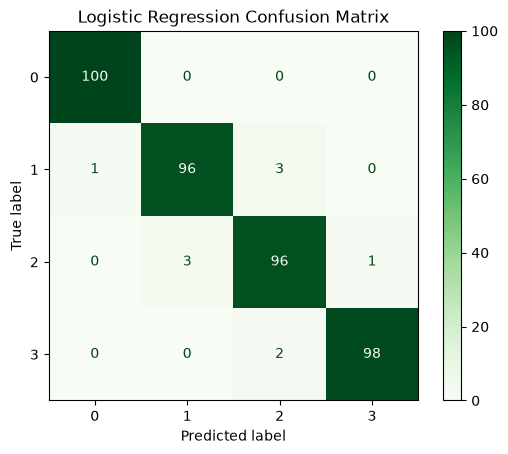

In [10]:
#Logistic Regression Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, lr_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3]
)

display.plot(cmap="Greens")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

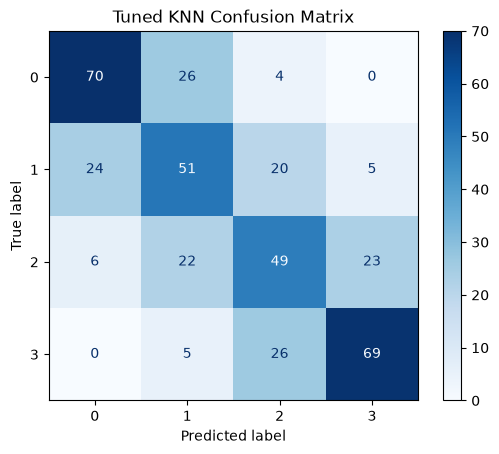

In [11]:
#KNN Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

knn_cm = confusion_matrix(y_val, knn_predictions)

knn_display = ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=[0, 1, 2, 3]
)

knn_display.plot(cmap="Blues")
plt.title("Tuned KNN Confusion Matrix")
plt.show()

In [12]:
#KNN Classification Report
from sklearn.metrics import classification_report

print("Tuned KNN Classification Report:")
print(classification_report(y_val, knn_predictions))

Tuned KNN Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.70      0.70       100
           1       0.49      0.51      0.50       100
           2       0.49      0.49      0.49       100
           3       0.71      0.69      0.70       100

    accuracy                           0.60       400
   macro avg       0.60      0.60      0.60       400
weighted avg       0.60      0.60      0.60       400



In [13]:
#Select Best Model
if lr_accuracy > knn_accuracy:
    best_model_name = "Logistic Regression"
    best_model = best_lr_model
else:
    best_model_name = "KNN"
    best_model = best_knn_model

print("Selected Best Model:", best_model_name)
print("Best Model Accuracy:", max(lr_accuracy, knn_accuracy) * 100)

Selected Best Model: Logistic Regression
Best Model Accuracy: 97.5


In [14]:
#Train Final Model
final_model = best_model

final_model.fit(X, y)

print("Final Model Training Completed Successfully!")

Final Model Training Completed Successfully!


In [15]:
import os

print("Current Notebook Location:")
print(os.getcwd())

Current Notebook Location:
C:\Users\RGUKT\Desktop\mobile_price_prediction\notebooks


In [16]:
print("Current Folder Contents:")
print(os.listdir(".."))

Current Folder Contents:
['.ipynb_checkpoints', 'data', 'document', 'notebooks', 'src']


In [17]:
import os

print(os.listdir("C:/Users/RGUKT"))

['-1.14-windows.xml', '.copilot', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.streamlit', '.vscode', '.vscode-shared', '3D Objects', 'AppData', 'Application Data', 'cleaned_student_dataset.csv', 'cleane_student_dataset.csv', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'movie prediction.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e80-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e80-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e80-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Recent', 'Saved Games', 'saved_models', 'Searches', 'SendTo', 'Start Menu', 'Student_Screen_Time_Dashboard.png', 'Templates', 'Titanic Survival prediction.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb', 'Untitled3.ipynb', 'Unti

In [18]:
import os
import joblib

save_path = r"C:\Users\RGUKT\Desktop\mobile_price_prediction\src\saved_models"

os.makedirs(save_path, exist_ok=True)

joblib.dump(
    final_model,
    os.path.join(save_path, "logistic_regression_model.pkl")
)

print("Model Saved Successfully!")
print("Location:", save_path)

Model Saved Successfully!
Location: C:\Users\RGUKT\Desktop\mobile_price_prediction\src\saved_models
